# Paper 04: Layer Normalization & RMSNorm
**Authors**: Jimmy Lei Ba, Jamie Ryan Kiros, Geoffrey E. Hinton (2016) & Biao Zhang, Rico Sennrich (2019)

---

## 1. The Historical Breaking Point
In Paper #3, we saw how **Batch Normalization** solved internal covariate shift in deep Feedforward and Convolutional networks by computing statistics along batch dimensions $(B, H, W)$.

However, BatchNorm broke down completely when applied to **Sequence Models** (RNNs, LSTMs, Transformers):
1. **Variable Sequence Lengths**: Sequences in a batch have different lengths $T$. Calculating batch statistics across time steps with zero-padding is mathematically flawed and noisy.
2. **Small Batch Sizes**: Batch statistics are erratic and unstable when $B$ is small ($B=1$ or $2$ during large model training / reinforcement learning / autoregressive generation).
3. **Inference Dependency**: BatchNorm requires tracking running buffers, coupling training dynamics to batch statistics that can differ widely at test time.

## 2. The First-Principles Solution: Layer Normalization
Instead of normalizing across different examples in a mini-batch, **Layer Normalization** normalizes across the **feature dimensions** independently for *each* individual example/token:

$$\mu = \frac{1}{D} \sum_{i=1}^D x_i, \quad \sigma^2 = \frac{1}{D} \sum_{i=1}^D (x_i - \mu)^2$$

$$\hat{x} = \frac{x - \mu}{\sqrt{\sigma^2 + \epsilon}}, \quad y = \gamma \odot \hat{x} + \beta$$

- Exactly the same computation at training time and inference time ($B=1$ works without buffers!).
- Completely invariant to batch size and sequence length.

## 3. The Modern LLM Evolution: RMSNorm (LLaMA / Gemma / Mistral)
Zhang & Sennrich (2019) discovered that the computational overhead of mean-centering $(\mu)$ is unnecessary. Scaling invariance alone provides all the regularization benefits:

$$\text{RMS}(x) = \sqrt{\frac{1}{D} \sum_{i=1}^D x_i^2 + \epsilon}$$

$$\bar{x} = \frac{x}{\text{RMS}(x)} \odot \gamma$$

RMSNorm drops the mean calculation and the bias $\beta$, reducing memory access and boosting LLM throughput by 10%–50%.

In this exercise, you will implement `LayerNorm` and `RMSNorm` in `model.py` and verify them below.

---
## Setup
`%autoreload 2` automatically reloads your code from `model.py` whenever you save changes.

In [1]:
%load_ext autoreload
%autoreload 2

import time
import math
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from model import LayerNorm, RMSNorm
import tests

---
## Part 1: LayerNorm Testing

We verify that your `LayerNorm`:
1. Standardizes each sample/token along feature dimensions independently (mean $\approx 0.0$, std $\approx 1.0$).
2. Correctly applies learnable affine scaling ($\gamma$) and shifting ($\beta$).
3. Achieves exact numerical equivalence against PyTorch's native `nn.LayerNorm`.

In [4]:
print("Testing LayerNorm Feature Standardization:")
tests.test_layernorm_feature_dim_stats(LayerNorm)

print("\nTesting LayerNorm Learnable Affine:")
tests.test_layernorm_affine(LayerNorm)

print("\nTesting Equivalence to PyTorch Native LayerNorm:")
tests.test_layernorm_equivalence_to_pytorch(LayerNorm)

Testing LayerNorm Feature Standardization:
  [PASS] LayerNorm correctly standardizes each sample/token independently (mean 0.0, std 1.0)!

Testing LayerNorm Learnable Affine:
  [PASS] LayerNorm affine parameters (gamma=3.0, beta=-2.0) scale and shift correctly!

Testing Equivalence to PyTorch Native LayerNorm:
  [PASS] Custom LayerNorm is mathematically identical to PyTorch LayerNorm (diff: 4.77e-07)!


True

---
## Part 2: RMSNorm Testing

We verify that your `RMSNorm` correctly computes the root mean square and scales inputs to unit RMS along the feature dimension.

In [8]:
print("Testing RMSNorm Scaling:")
tests.test_rmsnorm_scaling(RMSNorm)

Testing RMSNorm Scaling:
  [PASS] RMSNorm scales vectors to exact unit root-mean-square!


True

---
## Part 3: Deep Residual Dynamics & Throughput Comparison

Modern LLMs (GPT-3/4, LLaMA, Mistral, Gemma) stack 32–96 Transformer layers with residual connections:
$$x_{l+1} = x_l + \text{Block}(\text{Norm}(x_l))$$

Let's visualize two critical properties:
1. **Activation Stability**: How LayerNorm and RMSNorm prevent variance explosion across 20 deep sequential layers.
2. **Computational Speed**: Why modern LLM architects choose RMSNorm over LayerNorm (reduced memory bandwidth).

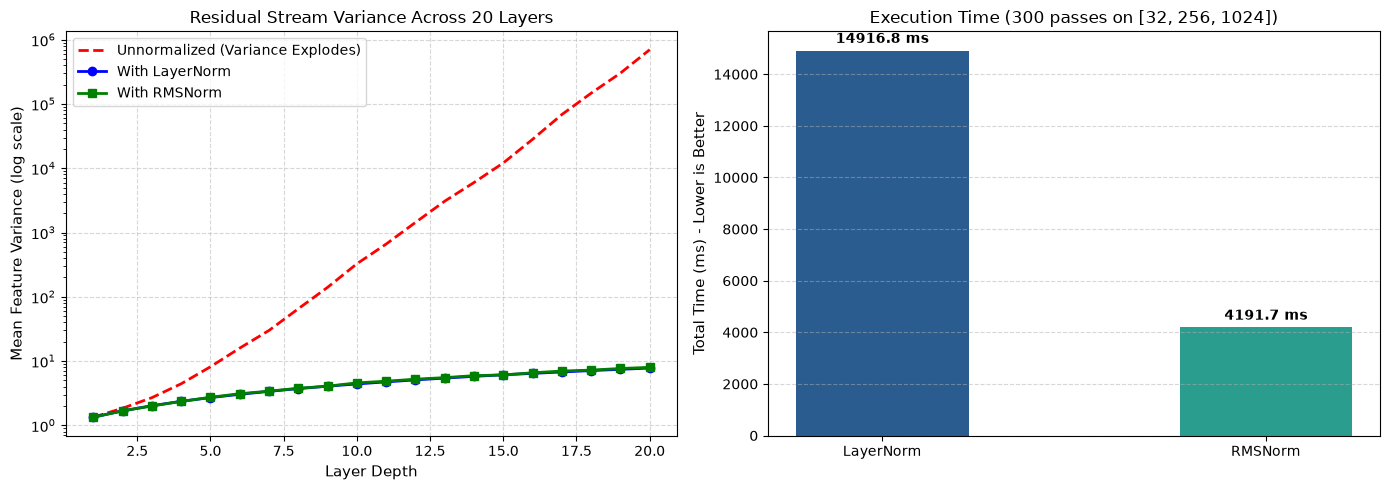

LayerNorm Time: 14916.79 ms | RMSNorm Time: 4191.73 ms (Speedup: 71.9%)


In [9]:
torch.manual_seed(42)
B, T, D = 16, 128, 512
num_layers = 20

# Track variance across layers for unnormalized vs LayerNorm vs RMSNorm
x_raw = torch.randn(B, T, D)
x_ln = x_raw.clone()
x_rms = x_raw.clone()

var_unnorm = []
var_ln = []
var_rms = []

ln_module = LayerNorm(D)
rms_module = RMSNorm(D)

for l in range(num_layers):
    # Simulate linear projection + residual step
    w = torch.randn(D, D) / math.sqrt(D)
    
    # Unnormalized
    x_raw = x_raw + torch.relu(x_raw @ w)
    var_unnorm.append(x_raw.var(dim=-1).mean().item())
    
    # LayerNorm
    x_ln = x_ln + torch.relu(ln_module(x_ln) @ w)
    var_ln.append(x_ln.var(dim=-1).mean().item())
    
    # RMSNorm
    x_rms = x_rms + torch.relu(rms_module(x_rms) @ w)
    var_rms.append(x_rms.var(dim=-1).mean().item())

# Benchmark throughput (500 forward passes)
bench_x = torch.randn(32, 256, 1024)
ln_bench = LayerNorm(1024)
rms_bench = RMSNorm(1024)

# Warmup
for _ in range(20):
    _ = ln_bench(bench_x)
    _ = rms_bench(bench_x)

iters = 300
t0 = time.perf_counter()
for _ in range(iters):
    _ = ln_bench(bench_x)
t_ln = (time.perf_counter() - t0) * 1000

t0 = time.perf_counter()
for _ in range(iters):
    _ = rms_bench(bench_x)
t_rms = (time.perf_counter() - t0) * 1000

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Activation Variance Explosion vs Control
ax1.plot(range(1, num_layers + 1), var_unnorm, 'r--', label='Unnormalized (Variance Explodes)', linewidth=2)
ax1.plot(range(1, num_layers + 1), var_ln, 'b-o', label='With LayerNorm', linewidth=2)
ax1.plot(range(1, num_layers + 1), var_rms, 'g-s', label='With RMSNorm', linewidth=2)
ax1.set_title('Residual Stream Variance Across 20 Layers', fontsize=12)
ax1.set_xlabel('Layer Depth', fontsize=11)
ax1.set_ylabel('Mean Feature Variance (log scale)', fontsize=11)
ax1.set_yscale('log')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(fontsize=10)

# Plot 2: Speedup Comparison
bars = ax2.bar(['LayerNorm', 'RMSNorm'], [t_ln, t_rms], color=['#2b5c8f', '#2a9d8f'], width=0.45)
ax2.set_title(f'Execution Time ({iters} passes on [32, 256, 1024])', fontsize=12)
ax2.set_ylabel('Total Time (ms) - Lower is Better', fontsize=11)
ax2.grid(True, axis='y', linestyle='--', alpha=0.5)
for bar in bars:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + (max(t_ln, t_rms) * 0.02), f'{h:.1f} ms', ha='center', fontweight='bold')

speedup = (t_ln - t_rms) / t_ln * 100
plt.tight_layout()
plt.show()

print(f"LayerNorm Time: {t_ln:.2f} ms | RMSNorm Time: {t_rms:.2f} ms (Speedup: {speedup:.1f}%)")